# Ligand-receptor analysis with bixverse

*Python port of the R vignette [Ligand-receptor analysis with bixverse](https://gregorlueg.github.io/bixverse/articles/ligand_receptor.html). Original author: Gregor Lueg.*

## Intro

This vignette runs two flavours of ligand-receptor analysis on the PBMC3k data
set. It assumes you know your way around the `SingleCells` class and the basic
processing pipeline. If not, have a look at the
[PBMC processing vignette](pbmc_single_cell.ipynb) first.

The two approaches answer different questions:

1. [CellPhoneDB](https://www.nature.com/articles/s41596-024-01137-1) asks which
   ligand-receptor pairs are expressed between two cell types, more so than
   you'd expect by chance. It works off expression alone, handles multi-subunit
   receptor complexes and comes with a curated database of ~2,900
   interactions.
2. [NicheNet](https://pubmed.ncbi.nlm.nih.gov/31819264/) goes one step further
   and asks which ligands best explain a downstream transcriptional response in
   the receiver. That needs a signalling and a gene regulatory network on top.

Both share the processing and the marker genes, so we do that once.

In [1]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
from bixverse.params import CellphonedbParams, LigandTargetParams

## Loading and processing PBMC3k

We reuse the standard processing pipeline. See the PBMC processing vignette
for commentary on each step.

In [2]:
pbmc3k_path = bv.io.download_pbmc3k()
tempdir_pbmc = tempfile.TemporaryDirectory()

sc = bv.io.load_mtx(
    Path(tempdir_pbmc.name) / "pbmc3k",
    bv.io.get_cell_ranger_params(pbmc3k_path),
)

sc.rename_var_col("column1", "gene_symbol")
var = sc.var()
symbol_to_ensembl = dict(zip(var["gene_symbol"], var["gene_id"], strict=True))
ensembl_to_symbol = dict(zip(var["gene_id"], var["gene_symbol"], strict=True))

# QC and processing
gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var.filter(pl.col("gene_symbol").str.contains("^RPS|^RPL"))[
        "gene_id"
    ].to_list(),
}
bv.qc.gene_set_proportions(sc, gs_of_interest)

# minimal cell filtering
cells_to_keep = sc.obs().filter(pl.col("MT") < 0.2)["cell_id"].to_list()
sc.set_cells_to_keep(cells_to_keep)

bv.pp.find_hvg(sc, hvg_no=2000)
bv.pp.calculate_pca(sc, no_pcs=30)
bv.graph.find_neighbours(sc)
bv.graph.find_clusters(sc, res=0.5)

Text pass (real): 1 buckets, ~2700 cells/bucket
Text pass done: 30.95ms (cell-major order)
Genes passing QC: 11_139 / 32_738
Cells passing QC: 2_700 / 2_700
Writing pass: 1 buckets, no sort
  Wrote bucket 1/1 (100%)
Writing pass done: 29.10ms
Converting the cell-based data into the gene-based format.


  Counted 2_269_399 non-zeros over 11_139 genes in 1.26ms; converting in 1 phase(s).
  Phase 1/1: genes 0-11139, scatter 5.76ms, compress + write 37.39ms
  Conversion into gene-friendly format done: 45.07ms


Load in data: 2.47ms
Finished the gene set proportion calculations: 699.88µs


HVG (VST): 11_139 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 3.68ms
HVG (VST): Fitted Loess in 551.58µs
HVG (VST): Standardised variance in 808.46µs (1_209 gene(s) re-read for the clip)
HVG (VST): Total run time -> 5.07ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 6.54ms
Sparse PCA: finished the data preparations in 949.67µs


Sparse PCA: finished calculations in 194.93ms
Sparse PCA: total run time -> 202.47ms
Generating kNN data with kmknn method.


Building kMkNN index ...


... built kMkNN index in 16.30ms
Generated KmKnn index: 16.44ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 5.66ms
Queried KmKnn index: 5.69ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 8.01ms


For demonstration purposes we use the Leiden cluster IDs directly as cell
types. In a real analysis you'd annotate the clusters first (marker genes, a
canonical panel, `bv.annotate.calc_sc_type_scores()`, take your pick). Senders
and receivers are biological concepts, and "cluster_3 talks to cluster_0"
doesn't tell anyone much.

In [3]:
sc.add_obs(
    sc.obs(cols=["cell_idx", "leiden_clustering"], filtered=True).select(
        "cell_idx",
        pl.format("cluster_{}", pl.col("leiden_clustering")).alias("celltype"),
    )
)

celltype_counts = (
    sc.obs(cols=["celltype"])
    .drop_nulls("celltype")
    .group_by("celltype")
    .len()
    .sort("len", descending=True)
)

celltype_counts

celltype,len
str,u32
"""cluster_0""",1194
"""cluster_1""",490
"""cluster_2""",459
"""cluster_3""",346
"""cluster_4""",164
"""cluster_5""",32
"""cluster_6""",13


Both methods want per-cluster marker genes, so let's get them out of the way.
`bv.de.find_all_markers()` runs a one-vs-rest Wilcoxon test per cluster.

In [4]:
celltype_de = bv.de.find_all_markers(sc, "celltype").rename(
    # rename to the schema the downstream functions expect
    {"gene_id": "gene", "grp": "cluster_id", "p_values": "pval"}
)

celltype_de.head()

  Progress: 17% (2_000 / 11_139 genes, 2.90ms)
  Progress: 26% (3_000 / 11_139 genes, 4.17ms)
  Progress: 35% (4_000 / 11_139 genes, 5.62ms)
  Progress: 44% (5_000 / 11_139 genes, 6.94ms)
  Progress: 53% (6_000 / 11_139 genes, 8.17ms)
  Progress: 62% (7_000 / 11_139 genes, 9.61ms)
  Progress: 71% (8_000 / 11_139 genes, 10.94ms)
  Progress: 80% (9_000 / 11_139 genes, 12.41ms)


  Progress: 98% (11_000 / 11_139 genes, 15.21ms)
  Progress: 100% (11_139 / 11_139 genes, 15.92ms)
One-vs-rest across 7 groups: 19.22ms


cluster_id,gene,lfc,prop1,prop2,z_scores,pval,fdr
str,str,f64,f64,f64,f64,f64,f64
"""cluster_0""","""ENSG00000188976""",-0.011828,0.090452,0.099734,-0.803301,0.789099,1.0
"""cluster_0""","""ENSG00000188290""",-0.141005,0.005025,0.091755,-9.942828,1.0,1.0
"""cluster_0""","""ENSG00000187608""",-0.500673,0.345896,0.526596,-11.483095,1.0,1.0
"""cluster_0""","""ENSG00000186891""",0.054344,0.053601,0.018617,4.928985,4.1329e-7,0.000005
"""cluster_0""","""ENSG00000186827""",0.181787,0.11474,0.011968,11.368363,3.0047e-30,9.5819e-29


## CellPhoneDB

### The database

`bv.lr.get_cellphonedb_db()` pulls the CellPhoneDB v5 database and flattens it
to one row per interaction. Each partner comes with the gene symbols of its
subunits: one gene for a plain protein, several for a complex.

In [5]:
cpdb_db = bv.lr.get_cellphonedb_db(verbose=False)

cpdb_db.group_by("directionality").len()

directionality,len
str,u32
"""Ligand-Receptor""",2508
"""Adhesion-Adhesion""",242
"""Receptor-Receptor""",28
"""Ligand-Ligand""",123
"""Gap-Gap""",10


A few receptors are complexes, e.g. the TGF-beta receptors:

In [6]:
cpdb_db.filter(pl.col("partner_a") == "TGFB1").select(
    "partner_a", "partner_b", "genes_b"
)

partner_a,partner_b,genes_b
str,str,list[str]
"""TGFB1""","""TGFbeta_receptor2""","[""ACVR1"", ""TGFBR2""]"
"""TGFB1""","""integrin_aVb6_complex""","[""ITGAV"", ""ITGB6""]"
"""TGFB1""","""TGFbeta_receptor1""","[""TGFBR1"", ""TGFBR2""]"
"""TGFB1""","""TGFBR3""","[""TGFBR3""]"


Got your own curated list? Any polars DataFrame with `interaction_id`,
`partner_a`, `partner_b` and the list columns `genes_a` and `genes_b` works.

### Statistical analysis

For every interaction and every ordered (sender, receiver) cluster pair,
partner a is measured in the sender and partner b in the receiver. The
interaction mean is the average of the two partner means, and a complex takes
the minimum over its subunits. Both partners need to be expressed in more than
10% of their cluster's cells (the gate). The p-value comes from shuffling the
cluster labels 1,000 times. The database speaks gene symbols, so we point
`gene_id_col` at the symbol column.

In [7]:
cpdb_res = bv.lr.cellphonedb(
    sc,
    "celltype",
    cpdb_db,
    gene_id_col="gene_symbol",
    params=CellphonedbParams(n_perm=1000),
)

cpdb_sig = cpdb_res.filter(pl.col("gate") & (pl.col("pval") <= 0.05))

cpdb_sig.height

Running CellPhoneDB: 158 interactions x 49 pairs (541 tested), 1_000 permutations
  Progress: 11% (112 / 1_000 permutations, 724.38µs)
  Progress: 20% (208 / 1_000 permutations, 1.40ms)
  Progress: 30% (304 / 1_000 permutations, 2.07ms)
  Progress: 40% (400 / 1_000 permutations, 2.58ms)
  Progress: 51% (512 / 1_000 permutations, 2.81ms)
  Progress: 60% (600 / 1_000 permutations, 3.42ms)
  Progress: 71% (712 / 1_000 permutations, 4.10ms)
  Progress: 80% (808 / 1_000 permutations, 4.60ms)
  Progress: 90% (904 / 1_000 permutations, 4.84ms)
  Progress: 100% (1_000 / 1_000 permutations, 5.46ms)
CellPhoneDB finished in 6.86ms


<@beartype(bixverse._core.lr.cellphonedb) at 0x10cc0ade0>:231: UserWarning: Dropping 2753 of 2911 interactions with subunits missing from `object`.


320

That's a lot of dropped interactions. `load_mtx()` throws out genes seen in
fewer than 10 cells, and much of CellPhoneDB (neurotransmitter transporters,
neuronal receptors, ...) is simply not expressed in blood:

In [8]:
cpdb_genes = pl.concat(
    [cpdb_db["genes_a"].explode(), cpdb_db["genes_b"].explode()]
).unique()

{
    "in_database": cpdb_genes.len(),
    "in_object": int(cpdb_genes.is_in(var["gene_symbol"].implode()).sum()),
}

{'in_database': 1354, 'in_object': 392}

An interaction needs every subunit of both partners, which leaves this many
interactions to test:

In [9]:
cpdb_res["interaction_id"].n_unique()

158

Which cluster pairs talk the most? Counting the significant interactions per
pair gives the classic CellPhoneDB heatmap.

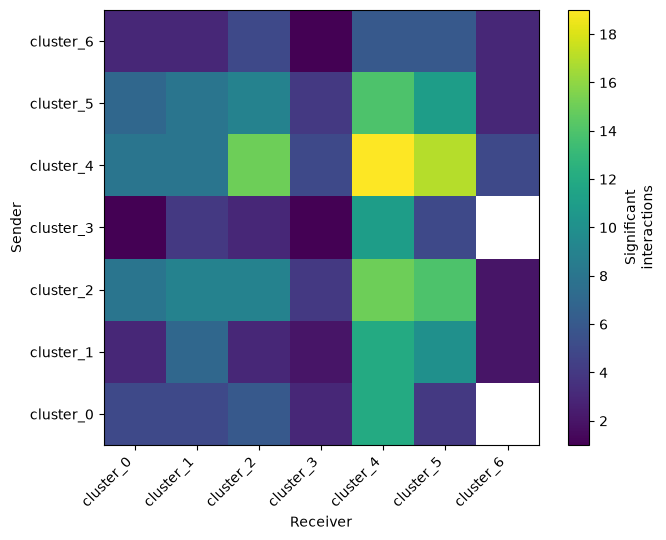

In [10]:
pair_counts = cpdb_sig.group_by("sender", "receiver").len()

clusters = sorted(
    set(pair_counts["sender"]) | set(pair_counts["receiver"]),
    key=lambda x: int(x.removeprefix("cluster_")),
)
heat = np.full((len(clusters), len(clusters)), np.nan)
pos = {c: i for i, c in enumerate(clusters)}
for s, r, n in pair_counts.iter_rows():
    heat[pos[s], pos[r]] = n

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(heat, cmap="viridis", origin="lower")
ax.set_xticks(range(len(clusters)), clusters, rotation=45, ha="right")
ax.set_yticks(range(len(clusters)), clusters)
ax.set_xlabel("Receiver")
ax.set_ylabel("Sender")
fig.colorbar(im, ax=ax, label="Significant\ninteractions")
fig.tight_layout()
plt.show()

And the strongest interactions by mean:

In [11]:
cpdb_sig.sort("mean", descending=True).select(
    "sender", "receiver", "partner_a", "partner_b", "mean", "pval"
).head(10)

sender,receiver,partner_a,partner_b,mean,pval
str,str,str,str,f64,f64
"""cluster_6""","""cluster_5""","""APP""","""CD74""",2.982131,0.0
"""cluster_6""","""cluster_3""","""APP""","""CD74""",2.918462,0.0
"""cluster_5""","""cluster_5""","""APP""","""CD74""",2.685051,0.0
"""cluster_6""","""cluster_5""","""PF4""","""CXCR3""",2.648153,0.0
"""cluster_5""","""cluster_3""","""APP""","""CD74""",2.621382,0.0
"""cluster_4""","""cluster_1""","""CD44""","""TYROBP""",2.550512,0.0
"""cluster_4""","""cluster_4""","""CD44""","""TYROBP""",2.454405,0.0
"""cluster_0""","""cluster_1""","""CD44""","""TYROBP""",2.40528,0.0
"""cluster_1""","""cluster_1""","""CD44""","""TYROBP""",2.369329,0.0


Two things to keep in mind here. First, the permutation test asks for
specificity, not just expression. Take PPIA-BSG: how many cluster pairs pass
the expression gate, and in how many is it significant?

In [12]:
ppia_bsg = (pl.col("partner_a") == "PPIA") & (pl.col("partner_b") == "BSG")
n_pairs = cpdb_res.select("sender", "receiver").unique().height

print(
    f"PPIA-BSG passes the gate in {cpdb_res.filter(ppia_bsg)['gate'].sum()} of "
    f"{n_pairs} cluster pairs, significant in {cpdb_sig.filter(ppia_bsg).height}"
)

PPIA-BSG passes the gate in 49 of 49 cluster pairs, significant in 20


Second, the top five of that list all involve clusters 5 or 6, the two
smallest ones:

In [13]:
celltype_counts.tail(2)

celltype,len
str,u32
"""cluster_5""",32
"""cluster_6""",13


Means over a handful of cells are noisy, so treat hits from tiny clusters
with care.

### DEG-based analysis

The alternative is CellPhoneDB's DEG-based method. No permutations here.
Instead, an interaction is kept for a pair if the expression gate passes and
partner a is a marker of the sender or partner b a marker of the receiver.
You decide what counts as a marker. Here we take genes with a log fold change
above 0.5 and FDR <= 0.05, and convert them to symbols to match the database.

In [14]:
deg_table = celltype_de.filter((pl.col("lfc") > 0.5) & (pl.col("fdr") <= 0.05)).select(
    "cluster_id", pl.col("gene").replace_strict(ensembl_to_symbol)
)

# same dropped interactions as above, no need to hear about them twice
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cpdb_deg_res = bv.lr.cellphonedb(
        sc,
        "celltype",
        cpdb_db,
        method="degs",
        deg_table=deg_table,
        gene_id_col="gene_symbol",
    )

cpdb_relevant = cpdb_deg_res.filter(pl.col("gate"))

cpdb_relevant.sort("mean", descending=True).select(
    "sender", "receiver", "partner_a", "partner_b", "mean"
).head(10)

sender,receiver,partner_a,partner_b,mean
str,str,str,str,f64
"""cluster_6""","""cluster_5""","""APP""","""CD74""",2.982131
"""cluster_6""","""cluster_3""","""APP""","""CD74""",2.918462
"""cluster_5""","""cluster_5""","""APP""","""CD74""",2.685051
"""cluster_6""","""cluster_5""","""PF4""","""CXCR3""",2.648153
"""cluster_5""","""cluster_3""","""APP""","""CD74""",2.621382
"""cluster_4""","""cluster_1""","""CD44""","""TYROBP""",2.550512
"""cluster_4""","""cluster_4""","""CD44""","""TYROBP""",2.454405
"""cluster_0""","""cluster_1""","""CD44""","""TYROBP""",2.40528
"""cluster_1""","""cluster_1""","""CD44""","""TYROBP""",2.369329


How many interaction and cluster pair combinations pass the DEG gate, and how
many of those are also significant in the permutation run?

In [15]:
overlap = cpdb_relevant.join(
    cpdb_sig, on=["interaction_id", "sender", "receiver"], how="inner"
)

{"deg_gate": cpdb_relevant.height, "also_significant": overlap.height}

{'deg_gate': 181, 'also_significant': 162}

This is the route to take if you've got a proper DE setup, e.g. pseudo-bulk
across samples (see the notes at the end). The cell type specificity then
comes from the DE test instead of from shuffling labels.

## NicheNet

NicheNet ranks upstream ligands by how well their predicted target genes line
up with a gene set of interest in a receiver cell type. The pipeline:

1. Build a ligand-target regulatory potential matrix from a signalling
   network (PPI) and a gene regulatory network (GRN).
2. Define a gene set of interest in the receiver (here, its marker genes).
3. Score each ligand by how well its targets overlap with that gene set
   (AUROC, AUPR, correlations).
4. Combine ligand activity with sender/receiver expression and DE into a
   single prioritisation score.

### Building the networks

A production analysis would load the curated NicheNet networks (signalling
and GRN) from [Zenodo](https://zenodo.org/records/7074291). To keep the
vignette self-contained, we construct a small network covering a handful of
canonical immune signalling pathways. The shape of the inputs is what matters
here... and it means you can feed in your own networks.

In [16]:
# Ligand-receptor pairs (canonical immune signalling)
lr_network = pl.DataFrame(
    {
        # ligands
        "from": ["CCL5", "CXCL10", "IL15", "TNF", "TGFB1", "IL10", "ICAM1"],
        # receptors
        "to": ["CCR5", "CXCR3", "IL2RG", "TNFRSF1A", "TGFBR2", "IL10RA", "ITGAL"],
        "weight": 1.0,
    }
)

# Signalling (PPI) layer: ligand -> receptor -> intracellular signalling -> TFs
ppi_network = pl.DataFrame(
    {
        "from": [
            "CCL5",
            "CXCL10",
            "IL15",
            "TNF",
            "TGFB1",
            "IL10",
            "ICAM1",
            "CCR5",
            "CXCR3",
            "IL2RG",
            "TNFRSF1A",
            "TGFBR2",
            "IL10RA",
            "ITGAL",
            "JAK1",
            "JAK2",
            "JAK3",
            "STAT1",
            "STAT3",
            "STAT5A",
            "NFKB1",
            "SMAD2",
        ],
        "to": [
            "CCR5",
            "CXCR3",
            "IL2RG",
            "TNFRSF1A",
            "TGFBR2",
            "IL10RA",
            "ITGAL",
            "JAK1",
            "JAK1",
            "JAK3",
            "NFKB1",
            "SMAD2",
            "JAK1",
            "NFKB1",
            "STAT1",
            "STAT3",
            "STAT5A",
            "STAT3",
            "STAT1",
            "STAT3",
            "STAT3",
            "STAT3",
        ],
        "weight": 1.0,
    }
)

# GRN layer: TF -> targets
grn_network = pl.DataFrame(
    {
        "from": ["STAT1"] * 6
        + ["STAT3"] * 6
        + ["STAT5A"] * 4
        + ["NFKB1"] * 6
        + ["SMAD2"] * 4,
        "to": [
            "IRF1",
            "MX1",
            "ISG15",
            "OAS1",
            "GBP1",
            "CXCL10",
            "SOCS3",
            "IL6",
            "BCL2",
            "VEGFA",
            "MYC",
            "FOS",
            "CCND1",
            "BCL2L1",
            "IL2RA",
            "FOXP3",
            "TNF",
            "IL1B",
            "IL6",
            "NFKBIA",
            "CCL5",
            "ICAM1",
            "SERPINE1",
            "CDKN1A",
            "JUNB",
            "ID1",
        ],
        "weight": 1.0,
    }
)

Restrict the networks to genes present in PBMC3k; the mapping to the Ensembl
IDs used internally comes later.

In [17]:
in_data = list(symbol_to_ensembl)


def keep_present(network: pl.DataFrame) -> pl.DataFrame:
    return network.filter(pl.col("from").is_in(in_data) & pl.col("to").is_in(in_data))


ppi_network = keep_present(ppi_network)
grn_network = keep_present(grn_network)
lr_network = keep_present(lr_network)

### Ligand-target regulatory potential

Construct the ligand-target influence matrix. Each row is one ligand and
each column is a gene from the union of both networks; entries are
NicheNet-style regulatory potential scores.

In [18]:
ligand_seeds = {lig: [lig] for lig in lr_network["from"]}

ligand_influence = bv.lr.generate_ligand_target_influence(
    ligand_seeds,
    pl.concat([lr_network, ppi_network]),
    grn_network,
    # because of the tiny network, the original ltf_cutoff of 0.99 would be way
    # too aggressive
    params=LigandTargetParams(ltf_cutoff=0.0),
)

ligand_influence

LigandTargetInfluence(
  n_ligands=6,
  n_genes=40,
  damping_factor=0.5,
  max_iter=1000,
  secondary_targets=False,
)

This returns a `LigandTargetInfluence`. The actual scores sit in a ligands x
genes array, with the names on `ligand_names` and `gene_ids`:

In [19]:
influence = bv.lr.get_influence(ligand_influence)

pl.DataFrame(influence, schema=list(ligand_influence.gene_ids)).insert_column(
    0, pl.Series("ligand", ligand_influence.ligand_names)
)

ligand,CCL5,CXCL10,IL15,TNF,TGFB1,ICAM1,CCR5,CXCR3,IL2RG,TNFRSF1A,TGFBR2,IL10RA,ITGAL,JAK1,JAK2,JAK3,STAT1,STAT3,STAT5A,NFKB1,SMAD2,IRF1,MX1,ISG15,OAS1,GBP1,SOCS3,IL6,BCL2,VEGFA,MYC,FOS,BCL2L1,IL2RA,FOXP3,IL1B,NFKBIA,CDKN1A,JUNB,ID1
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""CCL5""",0.0,0.083333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.083333,0.083333,0.083333,0.083333,0.083333,0.041667,0.041667,0.041667,0.041667,0.041667,0.041667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""CXCL10""",0.0,0.083333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.083333,0.083333,0.083333,0.083333,0.083333,0.041667,0.041667,0.041667,0.041667,0.041667,0.041667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""IL15""",0.0,0.020833,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.020833,0.020833,0.020833,0.020833,0.020833,0.041667,0.041667,0.041667,0.041667,0.041667,0.041667,0.0625,0.0625,0.0625,0.0,0.0,0.0,0.0,0.0
"""TNF""",0.125,0.041667,0.0,0.125,0.0,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.041667,0.041667,0.041667,0.041667,0.041667,0.083333,0.208333,0.083333,0.083333,0.083333,0.083333,0.0,0.0,0.0,0.125,0.125,0.0,0.0,0.0
"""TGFB1""",0.0,0.041667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.041667,0.041667,0.041667,0.041667,0.041667,0.083333,0.083333,0.083333,0.083333,0.083333,0.083333,0.0,0.0,0.0,0.0,0.0,0.125,0.125,0.125
"""ICAM1""",0.125,0.041667,0.0,0.125,0.0,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.041667,0.041667,0.041667,0.041667,0.041667,0.083333,0.208333,0.083333,0.083333,0.083333,0.083333,0.0,0.0,0.0,0.125,0.125,0.0,0.0,0.0


### Defining the gene set of interest

In a case/control experiment, the gene set of interest would be the DEGs
between conditions in the receiver cell type. PBMC3k is a single condition,
so we use the receiver's markers as a stand-in. We pick the largest cluster as
receiver and a few others as senders.

In [20]:
receiver_id = celltype_counts["celltype"][0]
senders_oi = celltype_counts["celltype"][1:5].to_list()

# upregulated genes with FDR <= 0.05 form the gene set
geneset_oi = celltype_de.filter(
    (pl.col("cluster_id") == receiver_id)
    & (pl.col("lfc") > 0)
    & (pl.col("fdr") <= 0.05)
)["gene"].to_list()

len(geneset_oi)

874

### Ligand activity scoring

Score each ligand by how well its target potential vector aligns with
`geneset_oi`. The background is the full set of genes in the influence
matrix.

In [21]:
activity = bv.lr.ligand_activity_scores(
    ligand_influence,
    # need to transform to gene symbols
    {"receiver_degs": [ensembl_to_symbol[g] for g in geneset_oi]},
)

activity.sort("aupr_corrected", descending=True)

gene_set,ligand,auroc,aupr,aupr_corrected,pearson,spearman
str,str,f64,f64,f64,f64,f64
"""receiver_degs""","""TGFB1""",0.659498,0.395679,0.170679,0.299473,0.266648
"""receiver_degs""","""IL15""",0.566308,0.23534,0.01034,0.117053,0.110854
"""receiver_degs""","""CCL5""",0.550179,0.229167,0.004167,-0.004046,0.090015
"""receiver_degs""","""CXCL10""",0.550179,0.229167,0.004167,-0.004046,0.090015
"""receiver_degs""","""TNF""",0.512545,0.208668,-0.016332,-0.004748,0.020256
"""receiver_degs""","""ICAM1""",0.512545,0.208668,-0.016332,-0.004748,0.020256


### Sender and receiver tables

Prioritisation needs the DE of ligands across senders and of receptors in the
receiver (we've got that from the markers), plus the average expression of
ligands and receptors per cluster. The latter calls into the streaming engine
via `bv.lr.compute_expression_info()`.

In [22]:
genes_of_interest = list(
    dict.fromkeys(lr_network["to"].to_list() + lr_network["from"].to_list())
)
genes_of_interest_ids = [symbol_to_ensembl[g] for g in genes_of_interest]

expression_info = bv.lr.compute_expression_info(sc, "celltype", genes_of_interest_ids)

expression_info.head()

cluster_id,gene,avg_expr,frac_expr
str,str,f64,f64
"""cluster_0""","""ENSG00000160791""",0.004314,0.00335
"""cluster_0""","""ENSG00000186810""",0.113563,0.064489
"""cluster_0""","""ENSG00000147168""",1.022484,0.538526
"""cluster_0""","""ENSG00000067182""",0.07514,0.045226
"""cluster_0""","""ENSG00000163513""",0.147678,0.085427


### Prioritisation

Combine all of the above into a single weighted score. PBMC3k has no
condition contrast, so we use the `"one_condition"` scenario, which sets
the condition-specificity weights to zero.

In [23]:
# Reduce activity table to one row per ligand (we ran one gene set)
la_input = activity.select(
    pl.col("ligand").replace_strict(symbol_to_ensembl), "aupr_corrected"
)

lr_network_ensembl = lr_network.select(
    pl.col("from").replace_strict(symbol_to_ensembl).alias("ligand"),
    pl.col("to").replace_strict(symbol_to_ensembl).alias("receptor"),
)

result = bv.lr.prioritise_interactions(
    celltype_de.select("cluster_id", "gene", "lfc", "pval"),
    expression_info,
    la_input,
    lr_network_ensembl,
    senders_oi,
    [receiver_id],
    scenario="one_condition",
)

Add symbol columns for readability.

In [24]:
result = result.with_columns(
    pl.col("ligand").replace_strict(ensembl_to_symbol).alias("ligand_symbol"),
    pl.col("receptor").replace_strict(ensembl_to_symbol).alias("receptor_symbol"),
)

result.select(
    "sender",
    "receiver",
    "ligand_symbol",
    "receptor_symbol",
    "prioritisation_score",
    "prioritisation_rank",
).head(10)

sender,receiver,ligand_symbol,receptor_symbol,prioritisation_score,prioritisation_rank
str,str,str,str,f64,u32
"""cluster_4""","""cluster_0""","""TGFB1""","""TGFBR2""",0.833333,1
"""cluster_1""","""cluster_0""","""TGFB1""","""TGFBR2""",0.783822,2
"""cluster_2""","""cluster_0""","""TGFB1""","""TGFBR2""",0.710455,3
"""cluster_1""","""cluster_0""","""IL15""","""IL2RG""",0.583003,4
"""cluster_3""","""cluster_0""","""TGFB1""","""TGFBR2""",0.55,5
"""cluster_4""","""cluster_0""","""IL15""","""IL2RG""",0.530964,6


### Top interactions

A quick dotplot of the top prioritised interactions.

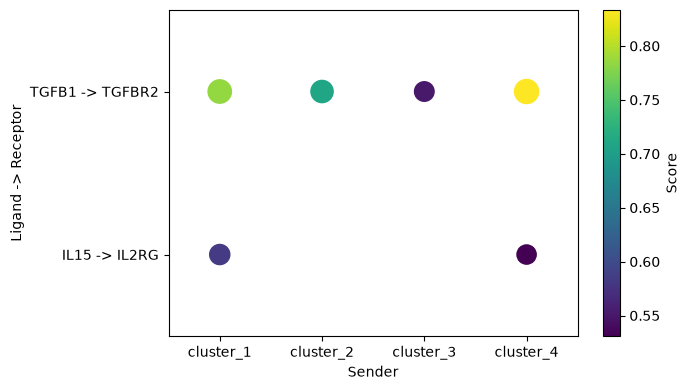

In [25]:
top_n = 15

plot_df = result.head(top_n).with_columns(
    pl.format("{} -> {}", "ligand_symbol", "receptor_symbol").alias("interaction")
)

senders = sorted(plot_df["sender"].unique())
interactions = sorted(plot_df["interaction"].unique())
x = [senders.index(s) for s in plot_df["sender"]]
y = [interactions.index(i) for i in plot_df["interaction"]]
score = plot_df["prioritisation_score"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 4))
pts = ax.scatter(x, y, s=300 * score / score.max(), c=score, cmap="viridis")
ax.set_xticks(range(len(senders)), senders)
ax.set_yticks(range(len(interactions)), interactions)
ax.set_xlim(-0.5, len(senders) - 0.5)
ax.set_ylim(-0.5, len(interactions) - 0.5)
ax.set_xlabel("Sender")
ax.set_ylabel("Ligand -> Receptor")
fig.colorbar(pts, ax=ax, label="Score")
fig.tight_layout()
plt.show()

## Notes on DE methods

`bv.de.find_all_markers()` runs a Wilcoxon test, which is convenient but
inflates p-values in single cell data: each cell is treated as an independent
observation. For inference that matters, go pseudo-bulk with DESeq2 or edgeR
style methods:

1. Aggregate counts per (sample, cluster) into pseudo-bulk.
2. Run a standard bulk DE pipeline.
3. Feed the result into `bv.lr.cellphonedb(method="degs")` as a `cluster_id`,
   `gene` table, or into `bv.lr.prioritise_interactions()` after renaming the
   columns to `cluster_id`, `gene`, `lfc`, `pval`.

Neither function cares which method produced the DE table.

## Clean up

In [26]:
tempdir_pbmc.cleanup()